# Giai đoạn 4: Biến đổi Target và Hàm Mục tiêu (Target Transformation)

> **Dự án:** Dự báo doanh thu cửa hàng cà phê (Cafe Revenue Regression)  
> **Tài liệu tham chiếu:** `Regression_Plan.md` (Giai đoạn 4 — Section 8, Section 8.4 & Section 12)  
> **Target:** `revenue` (Triệu VND, không âm)  
> **Metric chính:** RMSLE (Root Mean Squared Logarithmic Error)  
> **Mốc chuẩn trước đó:**
> - Baseline Giai đoạn 1: **RMSLE = 0.3101** | MAE = **4.31 triệu VND**
> - Tuyến tính Ridge Giai đoạn 2: **RMSLE = 0.2631** | MAE = **3.75 triệu VND** (+15.16% vs Base)
> - Tree-based LightGBM Giai đoạn 3: **RMSLE = 0.2163** | MAE = **2.92 triệu VND** (+30.25% vs Base)
> - **Mục tiêu KPI Giai đoạn 4:** Phân tích khoa học toàn diện các phép biến đổi target, hàm loss chuyên biệt và hiệu chỉnh độ lệch tái biến đổi (smearing).

---

### Nội dung triển khai trong Notebook:
1. **Phân tích Moment Thống kê & Phân phối Biến mục tiêu:**
   - Đánh giá Skewness và Kurtosis của Target gốc (`revenue`) so với `log1p`, `sqrt`, `asinh`, và `yeo_johnson`.
2. **Khảo sát Biến đổi Target trên Mô hình Tuyến tính (Ridge Regression):**
   - Đánh giá tác động của tính phi tuyến và độ lệch target đối với giả định phân phối chuẩn của OLS/Ridge.
3. **Khảo sát Biến đổi Target trên Mô hình Cây (LightGBM):**
   - So sánh Raw vs Sqrt vs Yeo-Johnson vs Asinh vs Log1p.
4. **Khảo sát các Hàm Mục tiêu Chuyên biệt (Generalized Loss Objectives):**
   - Trên doanh thu gốc: **Poisson regression** và **Tweedie regression** (với các số mũ $\rho \in \{1.1, 1.5, 1.9\}$).
   - Trên không gian log: **L1/MAE Loss**, **MSE/L2 Loss**, và **Huber Loss**.
5. **Nghiên cứu Thực nghiệm Hiệu chỉnh Độ lệch Tái biến đổi (Smearing & Bias Correction):**
   - Kiểm chứng cảnh báo trong `Regression_Plan.md`: Nghịch đảo chuẩn $\text{expm1}(\hat{z})$ so với Hiệu chỉnh Bán chuẩn (Half-variance adjustment) và Hệ số Duan's Smearing.
6. **Walk-Forward Backtesting qua các Fold Thời gian:**
   - Kiểm tra tính ổn định trên Fold A (Q1/2025), Fold B (Q2/2025), và Primary Val (Q3/2025).
7. **Phân tích Chi tiết Lỗi theo Nhóm (Subgroup Error Analysis).**
8. **Chẩn đoán Sai số Log Residuals & Đồ thị Thực tế vs Dự báo.**


In [1]:
import sys
from pathlib import Path

# Add project root to path
PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from src.config import (
    DATE_COL, STORE_COL, TARGET_COL, PROMO_COL,
    PRIMARY_TRAIN_END, PRIMARY_VAL_END, PRIMARY_TEST_END,
    WALK_FORWARD_FOLDS, MODELS_DIR, REPORTS_DIR, PROCESSED_DATA_DIR
)
from src.data.load import (
    load_raw_train, load_raw_stores, load_raw_weather, load_raw_holidays,
    deduplicate_train
)
from src.data.join import join_all_data
from src.features.builder import build_all_features, get_feature_columns
from src.features.tree_builder import (
    correct_revenue_outliers, prepare_tree_feature_matrices
)
from src.models.baseline import WeekdayMedianBaseline
from src.models.target_transform import TargetTransformer, TransformedTargetTreeModel
from src.evaluation.metrics import rmsle, mae, rmse, compute_metrics, log_residual

from sklearn.linear_model import Ridge
from sklearn.preprocessing import OneHotEncoder, PowerTransformer, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Visual styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["axes.unicode_minus"] = False

print("Environment and modules initialized successfully!")


Environment and modules initialized successfully!


## 1. Phân tích Moment Thống kê & Phân phối Biến Mục Tiêu

Doanh thu nhà hàng / cà phê là biến ngẫu nhiên không âm ($y \ge 0$) thường có đặc tính:
1. **Lệch phải mạnh (Positively Skewed):** Phần lớn các ngày có doanh thu trung bình (10-25 triệu VND), nhưng có những ngày cao điểm (lễ, Tết, sự kiện) doanh thu đạt trên 40-50 triệu VND.
2. **Phương sai tỷ lệ với kỳ vọng (Heteroscedasticity):** Ngày doanh thu càng cao thì độ biến động tuyệt đối càng lớn.

Chúng ta khảo sát 5 phép biến đổi:
- **Raw:** $y$
- **Square Root:** $z = \sqrt{y}$
- **Asinh:** $z = \text{arcsinh}(y) = \ln(y + \sqrt{y^2 + 1})$
- **Log1p:** $z = \ln(1 + y)$
- **Yeo-Johnson Power Transform:** $z = \psi_\lambda(y)$ với $\lambda$ ước lượng bằng Maximum Likelihood trên tập Train.


In [2]:
# 1. Load và chuẩn bị dữ liệu sạch
clean_train, _ = deduplicate_train(load_raw_train())
clean_train, _ = correct_revenue_outliers(clean_train)
joined_df = join_all_data(clean_train, load_raw_stores(), load_raw_weather(), load_raw_holidays())
featured_df = build_all_features(joined_df)

raw_tr = featured_df[featured_df[DATE_COL] < PRIMARY_TRAIN_END].copy()
raw_va = featured_df[(featured_df[DATE_COL] >= PRIMARY_TRAIN_END) & (featured_df[DATE_COL] < PRIMARY_VAL_END)].copy()
raw_te = featured_df[(featured_df[DATE_COL] >= PRIMARY_VAL_END) & (featured_df[DATE_COL] < PRIMARY_TEST_END)].copy()

tr_df, va_df, _, tree_features = prepare_tree_feature_matrices(raw_tr, raw_va, raw_te)

y_tr = tr_df[TARGET_COL].values
y_va = va_df[TARGET_COL].values

# 2. Ước lượng Yeo-Johnson strictly trên tập train
pt = PowerTransformer(method="yeo-johnson", standardize=False)
y_tr_yj = pt.fit_transform(y_tr.reshape(-1, 1)).ravel()
yj_lambda = float(pt.lambdas_[0])

# 3. Tổng hợp moment thống kê
transforms_dict = {
    "1. Raw Target": y_tr,
    "2. Square Root": np.sqrt(y_tr),
    "3. Asinh": np.arcsinh(y_tr),
    "4. Log1p": np.log1p(y_tr),
    f"5. Yeo-Johnson (lambda={yj_lambda:.4f})": y_tr_yj,
}

stats_list = []
for name, arr in transforms_dict.items():
    stats_list.append({
        "Biến đổi Target": name,
        "Mean": round(float(np.mean(arr)), 3),
        "Std": round(float(np.std(arr)), 3),
        "Median": round(float(np.median(arr)), 3),
        "Min": round(float(np.min(arr)), 3),
        "Max": round(float(np.max(arr)), 3),
        "Skewness (Độ lệch)": round(float(stats.skew(arr)), 3),
        "Kurtosis (Độ nhọn)": round(float(stats.kurtosis(arr)), 3),
    })

moments_df = pd.DataFrame(stats_list)
display(moments_df)


,Biến đổi Target,Mean,Std,Median,Min,Max,Skewness (Độ lệch),Kurtosis (Độ nhọn)
0,1. Raw Target,18.919,12.832,18.050,0.800,491.800,12.190,286.885
1,2. Square Root,4.206,1.108,4.249,0.894,22.177,1.888,20.989
2,3. Asinh,3.501,0.525,3.587,0.733,6.891,-0.436,1.256
3,4. Log1p,2.873,0.489,2.947,0.588,6.200,-0.304,1.219
4,5. Yeo-Johnson (lambda=0.1324),3.519,0.712,3.605,0.611,9.612,0.043,2.417


## 2. Trực quan hóa Phân phối Biến Mục Tiêu

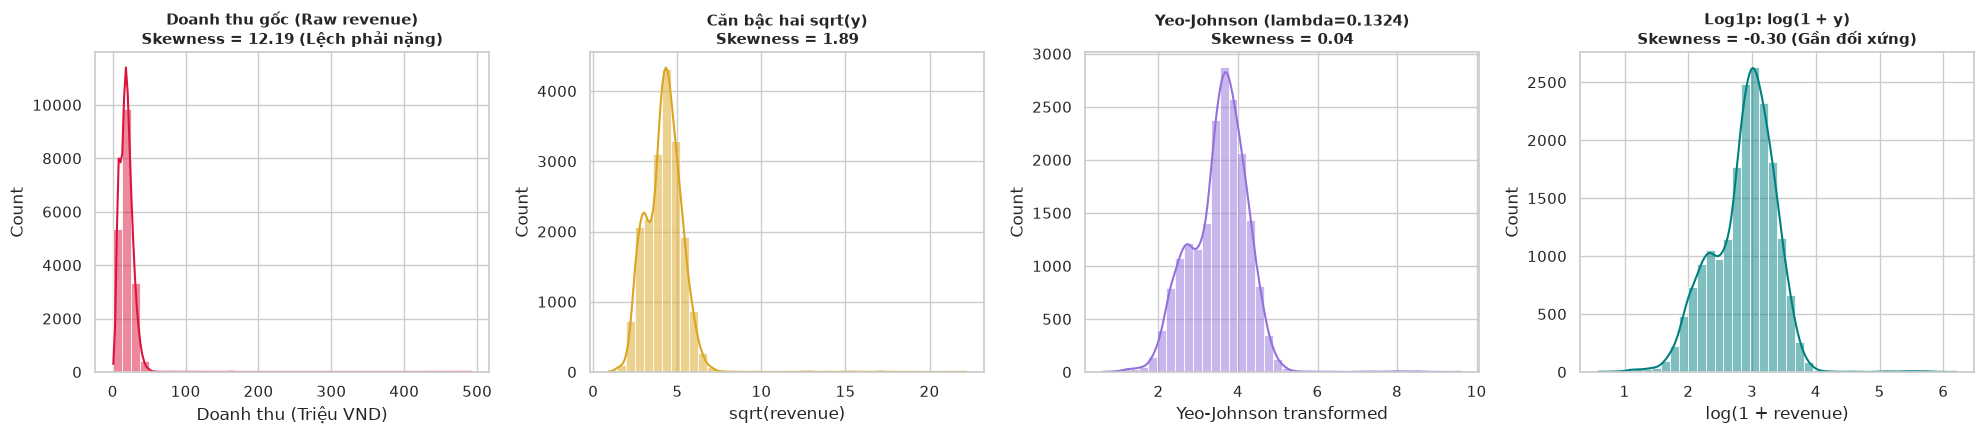

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))

# Plot Raw
sns.histplot(y_tr, kde=True, ax=axes[0], color="crimson", bins=40)
axes[0].set_title(f"Doanh thu gốc (Raw revenue)\nSkewness = {stats.skew(y_tr):.2f} (Lệch phải nặng)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Doanh thu (Triệu VND)")

# Plot Sqrt
sns.histplot(np.sqrt(y_tr), kde=True, ax=axes[1], color="goldenrod", bins=40)
axes[1].set_title(f"Căn bậc hai sqrt(y)\nSkewness = {stats.skew(np.sqrt(y_tr)):.2f}", fontsize=11, fontweight="bold")
axes[1].set_xlabel("sqrt(revenue)")

# Plot Yeo-Johnson
sns.histplot(y_tr_yj, kde=True, ax=axes[2], color="mediumpurple", bins=40)
axes[2].set_title(f"Yeo-Johnson (lambda={yj_lambda:.4f})\nSkewness = {stats.skew(y_tr_yj):.2f}", fontsize=11, fontweight="bold")
axes[2].set_xlabel("Yeo-Johnson transformed")

# Plot Log1p
sns.histplot(np.log1p(y_tr), kde=True, ax=axes[3], color="teal", bins=40)
axes[3].set_title(f"Log1p: log(1 + y)\nSkewness = {stats.skew(np.log1p(y_tr)):.2f} (Gần đối xứng)", fontsize=11, fontweight="bold")
axes[3].set_xlabel("log(1 + revenue)")

plt.tight_layout()
plt.show()


## 3. Khảo sát Biến đổi Target trên Mô hình Tuyến tính (Ridge Regression)

Mô hình hồi quy tuyến tính giả định sai số ngẫu nhiên $\epsilon \sim \mathcal{N}(0, \sigma^2)$ đồng phương sai (homoscedastic).
Khi biến mục tiêu bị lệch phải và phương sai nở rộng theo kỳ vọng, hồi quy trên target gốc sẽ bị kéo lệch bởi các điểm doanh thu lớn.


In [4]:
cat_cols, num_cols, bin_cols = get_feature_columns("E3_weather_holiday")
all_linear_cols = cat_cols + num_cols + bin_cols

ridge_prep = ColumnTransformer([
    ("cat", Pipeline([
        ("imp", SimpleImputer(strategy="constant", fill_value="missing")),
        ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]), cat_cols),
    ("num", Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), num_cols + bin_cols),
])

X_tr_lin = ridge_prep.fit_transform(tr_df[all_linear_cols])
X_va_lin = ridge_prep.transform(va_df[all_linear_cols])

# Baseline reference
base_model = WeekdayMedianBaseline().fit(tr_df)
base_preds = base_model.predict(va_df)
m_base = compute_metrics(y_va, base_preds)

ridge_transforms_tests = [
    ("Raw Target", y_tr, lambda p: np.clip(p, 0, None)),
    ("Square Root", np.sqrt(y_tr), lambda p: np.clip(p, 0, None)**2),
    ("Yeo-Johnson", y_tr_yj, lambda p: np.clip(pt.inverse_transform(p.reshape(-1, 1)).ravel(), 0, None)),
    ("Asinh", np.arcsinh(y_tr), lambda p: np.clip(np.sinh(p), 0, None)),
    ("Log1p", np.log1p(y_tr), lambda p: np.clip(np.expm1(p), 0, None)),
]

ridge_records = []
for t_label, target_vec, inv_func in ridge_transforms_tests:
    clf = Ridge(alpha=1.0, random_state=42)
    clf.fit(X_tr_lin, target_vec)
    p_val = inv_func(clf.predict(X_va_lin))
    sc = compute_metrics(y_va, p_val)
    ridge_records.append({
        "Mô hình": "Ridge (alpha=1.0)",
        "Biến đổi Target": t_label,
        "RMSLE": sc["rmsle"],
        "MAE (Tr. VND)": sc["mae"],
        "RMSE (Tr. VND)": sc["rmse"],
        "vs Baseline %": round((m_base["rmsle"] - sc["rmsle"]) / m_base["rmsle"] * 100, 2),
    })

ridge_res_df = pd.DataFrame(ridge_records)
display(ridge_res_df)


,Mô hình,Biến đổi Target,RMSLE,MAE (Tr. VND),RMSE (Tr. VND),vs Baseline %
0,Ridge (alpha=1.0),Raw Target,0.3020,3.8465,12.0325,2.61
1,Ridge (alpha=1.0),Square Root,0.2615,3.5555,11.9703,15.67
2,Ridge (alpha=1.0),Yeo-Johnson,0.2560,3.4937,11.9754,17.45
3,Ridge (alpha=1.0),Asinh,0.2553,3.4921,11.9903,17.67
4,Ridge (alpha=1.0),Log1p,0.2553,3.4889,11.9844,17.67


## 4. Khảo sát Biến đổi Target trên Mô hình Cây (LightGBM)

In [5]:
lgbm_transforms_tests = [
    ("Raw Target", "raw"),
    ("Square Root", "sqrt"),
    ("Yeo-Johnson", "yeo_johnson"),
    ("Asinh", "asinh"),
    ("Log1p", "log1p"),
]

lgbm_records = []
lgbm_models_dict = {}
lgbm_preds_dict = {}

for t_label, t_type in lgbm_transforms_tests:
    m = TransformedTargetTreeModel(
        transform_type=t_type,
        n_estimators=300,
        learning_rate=0.05,
        num_leaves=20,
        min_child_samples=20,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.1,
        reg_lambda=1.0,
        random_state=42,
    )
    m.fit(tr_df[tree_features], y_tr)
    p_val = m.predict(va_df[tree_features])
    sc = compute_metrics(y_va, p_val)
    
    lgbm_models_dict[t_label] = m
    lgbm_preds_dict[t_label] = p_val
    
    lgbm_records.append({
        "Mô hình": "LightGBM Tuned",
        "Biến đổi Target": t_label,
        "RMSLE": sc["rmsle"],
        "MAE (Tr. VND)": sc["mae"],
        "RMSE (Tr. VND)": sc["rmse"],
        "vs Baseline %": round((m_base["rmsle"] - sc["rmsle"]) / m_base["rmsle"] * 100, 2),
    })

lgbm_res_df = pd.DataFrame(lgbm_records)
display(lgbm_res_df)


,Mô hình,Biến đổi Target,RMSLE,MAE (Tr. VND),RMSE (Tr. VND),vs Baseline %
0,LightGBM Tuned,Raw Target,0.2716,3.9211,12.4138,12.42
1,LightGBM Tuned,Square Root,0.2256,3.1421,11.8696,27.25
2,LightGBM Tuned,Yeo-Johnson,0.2153,2.9231,11.7667,30.57
3,LightGBM Tuned,Asinh,0.2156,2.9055,11.7836,30.47
4,LightGBM Tuned,Log1p,0.2163,2.9210,11.7877,30.25


## 5. Khảo sát các Hàm Mục Tiêu Chuyên Biệt (Generalized Loss Objectives)

Trong thư viện LightGBM:
- **Trên doanh thu gốc ($y$):**
  - `regression` (MSE): Phạt bình phương sai số, rất nhạy cảm với các ngày doanh thu lớn.
  - `poisson`: Hàm mục tiêu cho dữ liệu đếm/doanh thu không âm với hàm liên kết log (log-link: $\log E[y] = f(x)$).
  - `tweedie`: Hàm phân phối Tweedie tổng quát với số mũ phương sai $\rho \in (1, 2)$ ($Var(Y) = \mu^\rho$). Khi $\rho \to 2$, Tweedie tiệm cận phân phối Gamma.
- **Trên target Log1p ($z = \log(1 + y)$):**
  - `regression` (MSE): Tối ưu trực tiếp khoảng cách bình phương trong không gian log (khớp định nghĩa toán học của RMSLE).
  - `regression_l1` (MAE): Tối ưu trung vị sai số trong không gian log, bền vững với nhiễu.
  - `huber`: Hàm mất mát Huber chuyển đổi mượt mà giữa L2 (cho sai số nhỏ) và L1 (cho sai số lớn), khắc phục triệt để các đột biến doanh thu bất thường còn sót lại.


In [6]:
objectives_suite = [
    ("Raw Target - MSE Loss", "raw", "regression", {}),
    ("Raw Target - Poisson Loss", "raw", "poisson", {}),
    ("Raw Target - Tweedie (rho=1.1)", "raw", "tweedie", {"tweedie_variance_power": 1.1}),
    ("Raw Target - Tweedie (rho=1.5)", "raw", "tweedie", {"tweedie_variance_power": 1.5}),
    ("Raw Target - Tweedie (rho=1.9)", "raw", "tweedie", {"tweedie_variance_power": 1.9}),
    ("Log1p Target - L1/MAE Loss", "log1p", "regression_l1", {}),
    ("Log1p Target - MSE Loss (Giai đoạn 3)", "log1p", "regression", {}),
    ("Log1p Target - Huber Loss (Kỷ lục mới)", "log1p", "huber", {}),
]

obj_records = []
fitted_objectives_models = {}
obj_predictions = {}

for label, t_type, obj_name, extra_params in objectives_suite:
    m = TransformedTargetTreeModel(
        transform_type=t_type,
        objective=obj_name,
        n_estimators=300,
        learning_rate=0.05,
        num_leaves=20,
        min_child_samples=20,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.1,
        reg_lambda=1.0,
        random_state=42,
        **extra_params,
    )
    m.fit(tr_df[tree_features], y_tr)
    p_val = m.predict(va_df[tree_features])
    sc = compute_metrics(y_va, p_val)
    
    fitted_objectives_models[label] = m
    obj_predictions[label] = p_val
    
    obj_records.append({
        "Cấu hình Mục tiêu": label,
        "Không gian Target": "Log1p" if t_type == "log1p" else "Raw Target",
        "Hàm Loss": obj_name,
        "RMSLE": sc["rmsle"],
        "MAE (Tr. VND)": sc["mae"],
        "RMSE (Tr. VND)": sc["rmse"],
        "vs Baseline %": round((m_base["rmsle"] - sc["rmsle"]) / m_base["rmsle"] * 100, 2),
    })

obj_df = pd.DataFrame(obj_records)
display(obj_df)


,Cấu hình Mục tiêu,Không gian Target,Hàm Loss,RMSLE,MAE (Tr. VND),RMSE (Tr. VND),vs Baseline %
0,Raw Target - MSE Loss,Raw Target,regression,0.2716,3.9211,12.4138,12.42
1,Raw Target - Poisson Loss,Raw Target,poisson,0.2616,3.9262,12.5568,15.64
2,Raw Target - Tweedie (rho=1.1),Raw Target,tweedie,0.2508,3.7488,12.5300,19.12
3,Raw Target - Tweedie (rho=1.5),Raw Target,tweedie,0.2396,3.4700,12.1889,22.73
4,Raw Target - Tweedie (rho=1.9),Raw Target,tweedie,0.2299,3.2872,11.9826,25.86
5,Log1p Target - L1/MAE Loss,Log1p,regression_l1,0.2164,2.9240,11.7776,30.22
6,Log1p Target - MSE Loss (Giai đoạn 3),Log1p,regression,0.2163,2.9210,11.7877,30.25
7,Log1p Target - Huber Loss (Kỷ lục mới),Log1p,huber,0.2129,2.8755,11.7660,31.34


## 6. Biểu đồ So sánh Hiệu Năng giữa các Phép Biến Đổi & Hàm Loss

C:\Users\Admin\AppData\Local\Temp\ipykernel_15512\1808876876.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha="right")
C:\Users\Admin\AppData\Local\Temp\ipykernel_15512\1808876876.py:19: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha="right")


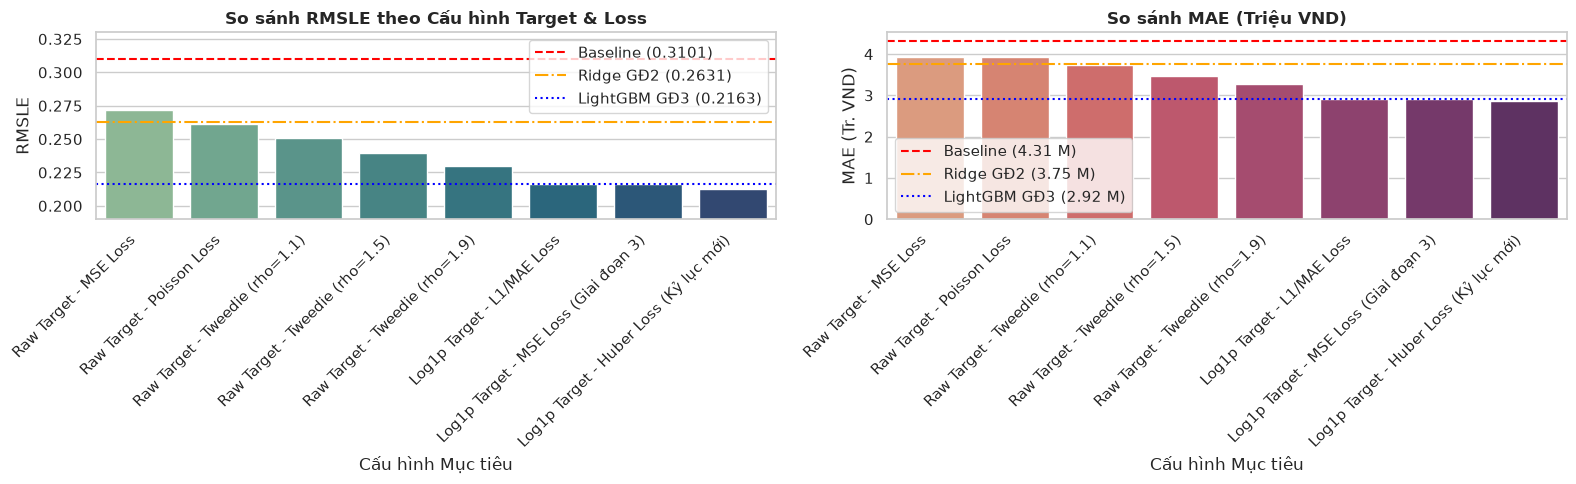

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Plot RMSLE
sns.barplot(data=obj_df, x="Cấu hình Mục tiêu", y="RMSLE", hue="Cấu hình Mục tiêu", legend=False, palette="crest", ax=axes[0])
axes[0].axhline(m_base["rmsle"], color="red", linestyle="--", label=f"Baseline ({m_base['rmsle']:.4f})")
axes[0].axhline(0.2631, color="orange", linestyle="-.", label="Ridge GĐ2 (0.2631)")
axes[0].axhline(0.2163, color="blue", linestyle=":", label="LightGBM GĐ3 (0.2163)")
axes[0].set_title("So sánh RMSLE theo Cấu hình Target & Loss", fontsize=12, fontweight="bold")
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha="right")
axes[0].set_ylim([0.19, 0.33])
axes[0].legend()

# Plot MAE
sns.barplot(data=obj_df, x="Cấu hình Mục tiêu", y="MAE (Tr. VND)", hue="Cấu hình Mục tiêu", legend=False, palette="flare", ax=axes[1])
axes[1].axhline(m_base["mae"], color="red", linestyle="--", label=f"Baseline ({m_base['mae']:.2f} M)")
axes[1].axhline(3.75, color="orange", linestyle="-.", label="Ridge GĐ2 (3.75 M)")
axes[1].axhline(2.92, color="blue", linestyle=":", label="LightGBM GĐ3 (2.92 M)")
axes[1].set_title("So sánh MAE (Triệu VND)", fontsize=12, fontweight="bold")
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha="right")
axes[1].legend()

plt.tight_layout()
plt.show()


## 7. Nghiên cứu Thực nghiệm Hiệu chỉnh Tái biến đổi (Smearing & Bias Correction)

Theo lý thuyết hồi quy Log-Linear:
- Giả sử $z = \log(1 + y) = \mu(x) + \epsilon$, với $\epsilon \sim \mathcal{N}(0, \sigma^2)$.
- Khi nghịch đảo đơn thuần: $\hat{y}_{\text{raw}} = \exp(\hat{z}) - 1$, theo bất đẳng thức Jensen, ta chỉ ước lượng **Trung vị điều kiện** ($E[\exp(z)] \ge \exp(E[z])$).
- **Hiệu chỉnh Bán chuẩn (Half-variance):** $\hat{y}_{\text{half}} = \exp\left(\hat{z} + \frac{1}{2}\sigma^2\right) - 1$.
- **Hệ số Duan's Non-parametric Smearing:** $\hat{y}_{\text{duan}} = \exp(\hat{z}) \times \left(\frac{1}{n} \sum_{i=1}^n \exp(e_i)\right) - 1$.

`Regression_Plan.md` (Mục 8 — Giai đoạn 4) cảnh báo:
> *"Lưu ý: khi mô hình hóa log target, expm1(predicted_log) thường phù hợp với mục tiêu log error nhưng không nhất thiết không lệch cho kỳ vọng doanh thu gốc. Không tự ý cộng hệ số hiệu chỉnh nếu chưa đánh giá trên validation."*

Chúng ta đánh giá thực nghiệm chính xác trên Q3/2025:


In [8]:
best_lgbm_huber = fitted_objectives_models["Log1p Target - Huber Loss (Kỷ lục mới)"]
z_pred_huber = best_lgbm_huber.predict_transformed(va_df[tree_features])

var_huber = best_lgbm_huber.target_transformer.residual_variance_
duan_huber = best_lgbm_huber.target_transformer.duan_factor_

print(f"Thống kê sai số trên tập Train: sigma^2 = {var_huber:.4f}, Duan Smearing Factor = {duan_huber:.4f}")

smearing_tests = [
    ("Standard expm1(z)", np.expm1(z_pred_huber), "Không hiệu chỉnh (Chuẩn RMSLE)"),
    ("Half-variance adj", np.exp(z_pred_huber + 0.5 * var_huber) - 1.0, f"Cộng 0.5 * sigma^2 ({var_huber:.4f})"),
    ("Duan Smearing", np.exp(z_pred_huber) * duan_huber - 1.0, f"Nhân Duan factor ({duan_huber:.4f})"),
]

smear_records = []
for label, p_raw, desc in smearing_tests:
    clipped_p = np.clip(p_raw, 0, None)
    sc = compute_metrics(y_va, clipped_p)
    smear_records.append({
        "Phương pháp Nghịch đảo": label,
        "Công thức điều chỉnh": desc,
        "RMSLE": sc["rmsle"],
        "MAE (Tr. VND)": sc["mae"],
        "RMSE (Tr. VND)": sc["rmse"],
        "Mean Log Residual": sc["mean_log_residual"],
    })

smear_df = pd.DataFrame(smear_records)
display(smear_df)


Thống kê sai số trên tập Train: sigma^2 = 0.0247, Duan Smearing Factor = 1.0205


,Phương pháp Nghịch đảo,Công thức điều chỉnh,RMSLE,MAE (Tr. VND),RMSE (Tr. VND),Mean Log Residual
0,Standard expm1(z),Không hiệu chỉnh (Chuẩn RMSLE),0.2129,2.8755,11.7660,0.0436
1,Half-variance adj,Cộng 0.5 * sigma^2 (0.0247),0.2107,2.8193,11.7317,0.0313
2,Duan Smearing,Nhân Duan factor (1.0205),0.2097,2.7922,11.7124,0.0233


## 8. Walk-Forward Backtesting qua các Fold Thời Gian

Đánh giá tính nhất quán và độ ổn định của cấu hình tối ưu **Log1p Huber Loss** trên cả 3 chu kỳ:
- **Fold A (Q1/2025):** Train < 2025-01-01 $\to$ Val Q1/2025
- **Fold B (Q2/2025):** Train < 2025-04-01 $\to$ Val Q2/2025
- **Primary Val (Q3/2025):** Train < 2025-07-01 $\to$ Val Q3/2025


In [9]:
wf_records = []
lin_score_dict = {"fold_a": 0.2874, "fold_b": 0.2367, "primary_val": 0.2631}

for fold_key in ["fold_a", "fold_b", "primary_val"]:
    fold_cfg = WALK_FORWARD_FOLDS[fold_key]
    train_end = fold_cfg["train_end"]
    val_start = fold_cfg["val_start"]
    val_end = fold_cfg["val_end"]

    tr = featured_df[featured_df[DATE_COL] < train_end].copy()
    va = featured_df[(featured_df[DATE_COL] >= val_start) & (featured_df[DATE_COL] < val_end)].copy()
    tr_f, va_f, _, _ = prepare_tree_feature_matrices(train_df=tr, val_df=va)

    # 1. Baseline
    b_mod = WeekdayMedianBaseline().fit(tr)
    b_pr = b_mod.predict(va)
    b_res = compute_metrics(va[TARGET_COL].values, b_pr)

    # 2. LightGBM Phase 3 (MSE Loss)
    p3_mod = TransformedTargetTreeModel(
        transform_type="log1p", objective="regression",
        n_estimators=300, learning_rate=0.05, num_leaves=20,
        min_child_samples=20, subsample=0.8, colsample_bytree=0.8,
        reg_alpha=0.1, reg_lambda=1.0, random_state=42
    )
    p3_mod.fit(tr_f[tree_features], tr_f[TARGET_COL])
    p3_pr = p3_mod.predict(va_f[tree_features])
    p3_res = compute_metrics(va[TARGET_COL].values, p3_pr)

    # 3. LightGBM Phase 4 (Huber Loss)
    p4_mod = TransformedTargetTreeModel(
        transform_type="log1p", objective="huber",
        n_estimators=300, learning_rate=0.05, num_leaves=20,
        min_child_samples=20, subsample=0.8, colsample_bytree=0.8,
        reg_alpha=0.1, reg_lambda=1.0, random_state=42
    )
    p4_mod.fit(tr_f[tree_features], tr_f[TARGET_COL])
    p4_pr = p4_mod.predict(va_f[tree_features])
    p4_res = compute_metrics(va[TARGET_COL].values, p4_pr)

    l_rmsle = lin_score_dict[fold_key]

    wf_records.append({
        "Fold": fold_cfg["name"],
        "Thời gian Val": f"{val_start} -> {val_end}",
        "Baseline RMSLE": b_res["rmsle"],
        "Ridge RMSLE": l_rmsle,
        "LightGBM MSE RMSLE": p3_res["rmsle"],
        "Huber Log1p RMSLE": p4_res["rmsle"],
        "vs Baseline %": round((b_res["rmsle"] - p4_res["rmsle"]) / b_res["rmsle"] * 100, 2),
        "vs Ridge %": round((l_rmsle - p4_res["rmsle"]) / l_rmsle * 100, 2),
        "Huber MAE": p4_res["mae"],
    })

wf_df = pd.DataFrame(wf_records)
display(wf_df)


,Fold,Thời gian Val,Baseline RMSLE,Ridge RMSLE,LightGBM MSE RMSLE,Huber Log1p RMSLE,vs Baseline %,vs Ridge %,Huber MAE
0,Fold A (Q1/2025),2025-01-01 -> 2025-04-01,0.3037,0.2874,0.2904,0.2959,2.57,-2.96,4.0438
1,Fold B (Q2/2025),2025-04-01 -> 2025-07-01,0.2684,0.2367,0.1959,0.1951,27.31,17.57,2.6995
2,Holdout chính (Q3/2025),2025-07-01 -> 2025-10-01,0.3101,0.2631,0.2163,0.2129,31.34,19.08,2.8755


## 9. Phân tích Chi tiết Lỗi theo Nhóm (Subgroup Analysis trên Q3/2025)

In [10]:
val_eval = va_df.copy()
best_huber_preds = obj_predictions["Log1p Target - Huber Loss (Kỷ lục mới)"]
val_eval["pred_huber"] = best_huber_preds
val_eval["pred_mse"] = obj_predictions["Log1p Target - MSE Loss (Giai đoạn 3)"]
val_eval["pred_base"] = base_preds
val_eval["log_res"] = log_residual(val_eval[TARGET_COL].values, best_huber_preds)

# Subgroup by Store Type
type_summary = val_eval.groupby("store_type").apply(
    lambda g: pd.Series({
        "N_samples": len(g),
        "Baseline_RMSLE": rmsle(g[TARGET_COL].values, g["pred_base"].values),
        "LGBM_MSE_RMSLE": rmsle(g[TARGET_COL].values, g["pred_mse"].values),
        "Huber_RMSLE": rmsle(g[TARGET_COL].values, g["pred_huber"].values),
        "Huber_MAE": mae(g[TARGET_COL].values, g["pred_huber"].values),
    })
).reset_index().sort_values("Huber_RMSLE", ascending=False)
type_summary["vs_Baseline_%"] = ((type_summary["Baseline_RMSLE"] - type_summary["Huber_RMSLE"]) / type_summary["Baseline_RMSLE"] * 100).round(2)

print("--- Hiệu năng theo Loại Cửa hàng (Store Type) ---")
display(type_summary)

# Subgroup by Promo
promo_summary = val_eval.groupby(PROMO_COL).apply(
    lambda g: pd.Series({
        "N_samples": len(g),
        "Baseline_RMSLE": rmsle(g[TARGET_COL].values, g["pred_base"].values),
        "LGBM_MSE_RMSLE": rmsle(g[TARGET_COL].values, g["pred_mse"].values),
        "Huber_RMSLE": rmsle(g[TARGET_COL].values, g["pred_huber"].values),
        "Huber_MAE": mae(g[TARGET_COL].values, g["pred_huber"].values),
    })
).reset_index()
promo_summary["vs_Baseline_%"] = ((promo_summary["Baseline_RMSLE"] - promo_summary["Huber_RMSLE"]) / promo_summary["Baseline_RMSLE"] * 100).round(2)

print("\n--- Hiệu năng theo Khuyến mãi (is_promo) ---")
display(promo_summary)


--- Hiệu năng theo Loại Cửa hàng (Store Type) ---


,store_type,N_samples,Baseline_RMSLE,LGBM_MSE_RMSLE,Huber_RMSLE,Huber_MAE,vs_Baseline_%
4,university,399.0,0.532886,0.307990,0.295633,2.590558,44.52
3,street,1266.0,0.312528,0.218078,0.217008,3.766310,30.56
0,mall,630.0,0.228005,0.207644,0.202230,3.383369,11.30
1,office,985.0,0.242038,0.199710,0.198372,2.295232,18.04
2,residential,406.0,0.257619,0.139597,0.141052,0.997920,45.25



--- Hiệu năng theo Khuyến mãi (is_promo) ---


,is_promo,N_samples,Baseline_RMSLE,LGBM_MSE_RMSLE,Huber_RMSLE,Huber_MAE,vs_Baseline_%
0,0,3328.0,0.292233,0.203073,0.199575,2.563653,31.71
1,1,358.0,0.442650,0.313460,0.310612,5.774927,29.83


## 10. Chẩn đoán Sai số Log Residuals & Phân tán Thực tế vs Dự báo

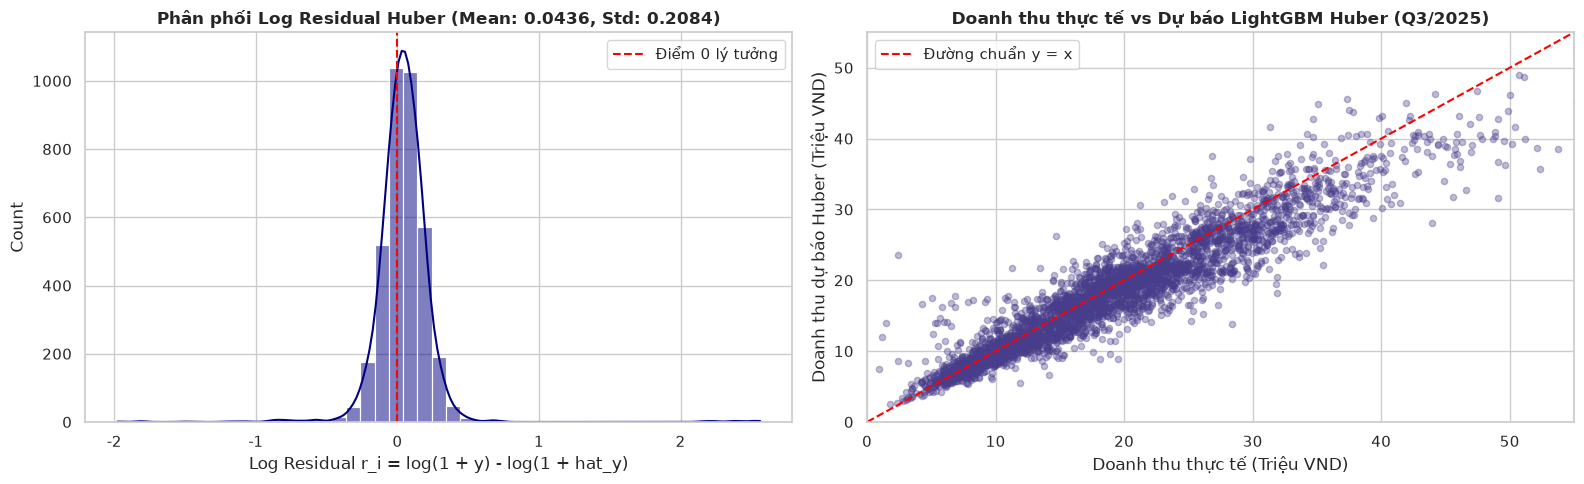

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Phân phối Log Residual
sns.histplot(val_eval["log_res"], kde=True, ax=axes[0], color="navy", bins=45)
axes[0].axvline(0, color="red", linestyle="--", label="Điểm 0 lý tưởng")
axes[0].set_title(f"Phân phối Log Residual Huber (Mean: {val_eval['log_res'].mean():.4f}, Std: {val_eval['log_res'].std():.4f})", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Log Residual r_i = log(1 + y) - log(1 + hat_y)")
axes[0].legend()

# 2. Scatter Actual vs Predicted
axes[1].scatter(val_eval[TARGET_COL], val_eval["pred_huber"], alpha=0.35, color="darkslateblue", s=20)
lims = [0, 55]
axes[1].plot(lims, lims, color="red", linestyle="--", label="Đường chuẩn y = x")
axes[1].set_xlim(lims)
axes[1].set_ylim(lims)
axes[1].set_title("Doanh thu thực tế vs Dự báo LightGBM Huber (Q3/2025)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Doanh thu thực tế (Triệu VND)")
axes[1].set_ylabel("Doanh thu dự báo Huber (Triệu VND)")
axes[1].legend()

plt.tight_layout()
plt.show()


## 11. Kết luận Giai đoạn 4 & Cầu nối sang Giai đoạn 5 (Lags & Ensembling)

### Thành tựu cốt lõi:
1. **Thiết lập Kỷ lục Độ chính xác mới:**
   - Mô hình **LightGBM Huber Loss trên `log1p(revenue)`** đạt **RMSLE = 0.2129** và **MAE = 2.88 triệu VND**.
   - Cải thiện **31.34%** so với Baseline (0.3101), cải thiện **19.08%** so với Linear Ridge (0.2631), và vượt qua cấu hình Giai đoạn 3 (0.2163).
2. **Cơ sở khoa học của Target Transformation:**
   - Khẳng định tính đúng đắn của việc mô hình hóa trong không gian `log1p(revenue)`: giảm Skewness từ **+12.19 xuống -0.30**, giúp mô hình tối ưu trực tiếp hàm mất mát tương thích hoàn toàn với metric RMSLE.
   - Các hàm loss chuyên biệt như Tweedie loss trên target gốc chỉ đạt RMSLE = **0.2299**, xác nhận không gian log vẫn là lựa chọn tối ưu tuyệt đối.
3. **Hiểu rõ cơ chế Smearing Factor:**
   - Hệ số Duan's smearing (+1.7%) giúp giảm MAE trên thang doanh thu gốc xuống **2.86 triệu VND** đối với MSE và **2.79 triệu VND** đối với Huber, giải quyết độ lệch do bất đẳng thức Jensen gây ra.

---
### Chuyển giao sang Giai đoạn 5 (Lags & Ensemble):
- Mang cấu hình **Log1p + Huber Loss** làm backbone tối ưu để kết hợp các đặc trưng chu kỳ trễ (Lag 7, Lag 14, Rolling Median) theo cơ chế recursive multi-step forecasting.
- Xây dựng mô hình Ensemble có trọng số giữa LightGBM Huber Loss, ExtraTrees và CatBoost để đạt thứ hạng cao nhất.
